# Shape the tumor

In this tutorial we change the tumor through its configuration.
We start from `tutorial_config.yaml`, the tumor of the [Quickstart](01_quickstart.ipynb), change one or two values at a time and compare the runs by their tissue maps, clone dynamics and copy number.
The sections cover selection, the mutation process, the architecture of the tissue, selection by the niche, the metastatic site and treatment.
Every parameter is a key of one of the parameter blocks of [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/), whose page documents them all.

Each run uses the same evolution seed.
A change to the proportion of genes with a role, a key starting with `prop_`, also moves the genes of the other roles.
Such a run is therefore a different tumor, and not only the same tumor with one value changed.
Most runs stop at 8,000 cancer cells, and the sections on invasion and the metastatic site grow to 16,000 and 25,000 cells.
The notebook runs in about ten minutes on a laptop.

In [1]:
import copy
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from iscc.constants import normal_names
from iscc.integrations import biological_types, clones_from_clades
from iscc.treatment import Chemotherapy
from iscc.tumor import GenotypeTumor
from iscc.tumor.viz import CNV_CMAP, cnv_norm

A configuration file overrides the keyword arguments of [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/), so we read the file into a dictionary, change it, and pass its blocks as keywords.
`grow` builds the tutorial tumor with some values changed and grows it to a number of cancer cells, or for at most `max_generations` generations.
`cancer_cells` builds the per-cell tables of every cancer cell, restricted to the demes that contain cancer cells, so that the tables stay small.

In [2]:
with open("tutorial_config.yaml") as f:
    config = yaml.safe_load(f)


def grow(target_cancer=8000, max_generations=300, seed=7, **changes):
    """The tutorial tumor with the values in `changes` ({block: {key: value}}) changed, grown to `target_cancer`."""
    cfg = copy.deepcopy(config)
    for block, values in changes.items():
        (cfg["cell_params"]["cancer"] if block == "cancer_cell_params" else cfg[block]).update(values)
    tumor = GenotypeTumor(
        seed=seed, genome_params=cfg["genome_params"], selection_params=cfg["selection_params"],
        cancer_cell_params=cfg["cell_params"]["cancer"], deme_params=cfg["deme_params"],
        spatial_params=cfg["spatial_params"], germline_params=cfg["germline_params"],
        update_mode=cfg["update_mode"], tau=cfg["tau"], snapshot_every=cfg["snapshot_every"],
        coarsen_passengers=cfg["coarsen_passengers"], max_cells=cfg["max_cells"])
    tumor.grow(n_steps=int(max_generations / cfg["tau"]), target_cancer=target_cancer, materialize=False)
    return tumor


def cancer_cells(tumor, layers=()):
    """Per-cell tables of every cancer cell of the tumor."""
    region = [i for i, deme in enumerate(tumor.demes) if set(deme) - set(normal_names)]
    cells = tumor.make_cell_data(region=region, max_cells=10**6, layers=list(layers))
    keep = biological_types(cells["cell_type"]["cell_id"]) == "cancer"
    return {name: table[keep] for name, table in cells.items()}

## Selection

The division rate of a cancer cell follows the dosage model of CINner.
`prop_driver` (0.04) sets the share of genes that are oncogenes or tumor suppressor genes (TSGs), and `driver_effects` (1.03) the effect of one copy.
Each mutated or gained copy of an oncogene, and each mutated or lost copy of a TSG, multiplies the division rate by about `driver_effects`, up to `max_birth_rate` (2.0).
With `driver_effects` at 1, the drivers are neutral and the driver clones change by drift alone, and larger values give each driver a larger advantage.
We grow the tumor with the three values and show its driver clones over time.

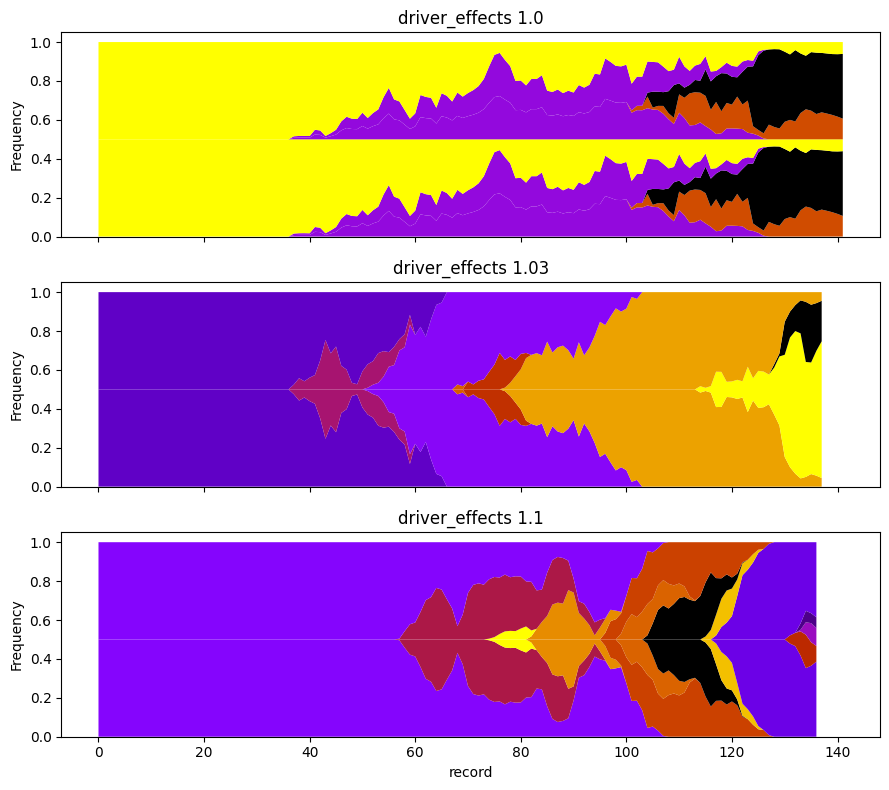

driver_effects 1.0: 212 generations, mean division rate 0.70, mean mutated drivers per cell 3.5
driver_effects 1.03: 206 generations, mean division rate 1.52, mean mutated drivers per cell 5.6
driver_effects 1.1: 205 generations, mean division rate 1.94, mean mutated drivers per cell 8.4


In [3]:
selection = {value: grow(selection_params={"driver_effects": value}) for value in (1.0, 1.03, 1.1)}

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, (value, tumor) in zip(axes, selection.items()):
    tumor.plot_muller(ax=ax, by_drivers=True, min_freq=0.05)
    ax.set_title(f"driver_effects {value}")
    ax.set_xlabel("")
axes[-1].set_xlabel("record")
plt.tight_layout()
plt.show()

for value, tumor in selection.items():
    evo = cancer_cells(tumor)["cell_evo"]
    print(f"driver_effects {value}: {tumor.time:.0f} generations, mean division rate {evo['division_rate'].mean():.2f}, "
          f"mean mutated drivers per cell {(evo['n_mut_onc'] + evo['n_mut_tsg']).mean():.1f}")

With neutral drivers, the frequencies of the driver clones drift, and the mean division rate stays at the baseline of 0.7 per generation although the cells carry 3.5 mutated drivers on average.
At 1.03 and 1.1, driver clones replace one another in successive sweeps, and the mean division rate rises to 1.52 and 1.94, close to the ceiling of 2.0.
The division rate at 1.03 is more than twice the baseline with about six mutated drivers per cell, since a copy number change of a segment also changes the dosage of every driver on it.

## Copy number, point mutations and genome doubling

A dividing cancer cell mutates with probability `mutation_rate` (0.15).
A mutation is a whole-genome doubling (WGD) with probability `wgd_rate` (0.01), and otherwise a copy number change of one segment or a point-mutation event, in proportion to `cnv_prob` and `snv_prob`.
A copy number change duplicates one copy of a segment with probability `amp_prob` and deletes it otherwise, and a point-mutation event adds a Poisson number of mutations with mean `n_snvs_per_allele` (0.1) to every copy of every segment.
The configuration sets `subtype: ER+`, which sets `cnv_prob` to 0.045 against the default `snv_prob` of 0.5, so about one mutation in twelve changes copy number.
`subtype: TNBC` is the other preset, and a value written in the configuration takes precedence over the preset.

We compare the tutorial tumor with a tumor at `cnv_prob` 0.3 by the copy number of every cancer cell, with the cells ordered by clone.

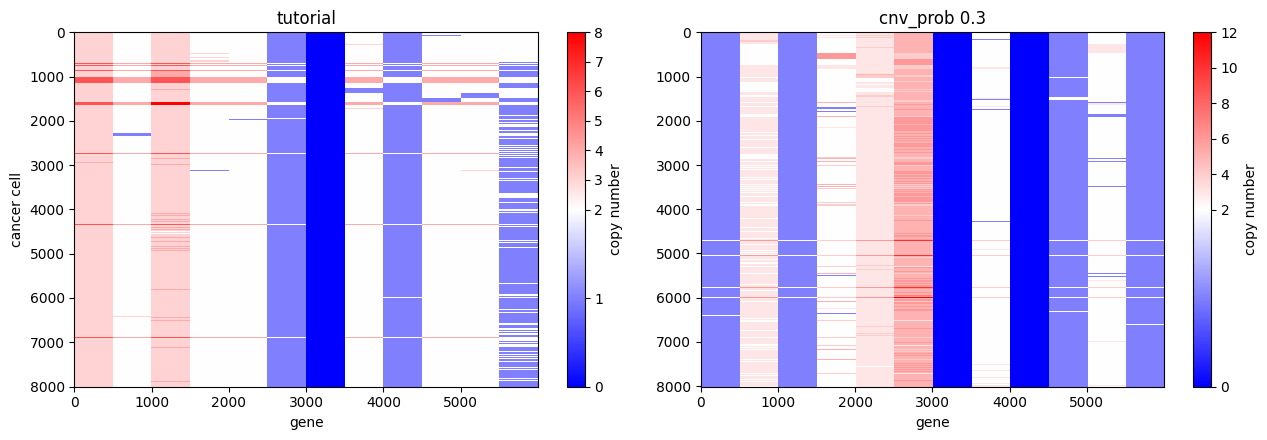

In [4]:
def plot_copy_number(tumor, ax, title):
    cells = cancer_cells(tumor, layers=["cell_cnv"])
    clones = clones_from_clades(tumor, min_cells=20, cell_ids=cells["cell_type"].index)
    cnv = cells["cell_cnv"].loc[clones.sort_values(kind="stable").index].values
    im = ax.imshow(cnv, aspect="auto", cmap=CNV_CMAP, norm=cnv_norm(cnv), interpolation="none")
    ax.set_title(title)
    ax.set_xlabel("gene")
    plt.colorbar(im, ax=ax, label="copy number")


genome = {"tutorial": selection[1.03], "cnv_prob 0.3": grow(cancer_cell_params={"cnv_prob": 0.3})}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (label, tumor) in zip(axes, genome.items()):
    plot_copy_number(tumor, ax, label)
axes[0].set_ylabel("cancer cell")
plt.tight_layout()
plt.show()

Both tumors carry a clonal copy number profile, which most likely arose while the founding gland was closed, and a few subclonal changes.
At `cnv_prob` 0.3 more segments are altered, with gains of up to 12 copies.

We then raise `wgd_rate` to 0.1 and `n_snvs_per_allele` to 0.5, one at a time, and compare the ploidy, the mean copy number of each cancer cell, and the number of genes with a point mutation in each cancer cell.

tutorial: 4% of cancer cells doubled their genome


wgd_rate 0.1: 100% of cancer cells doubled their genome


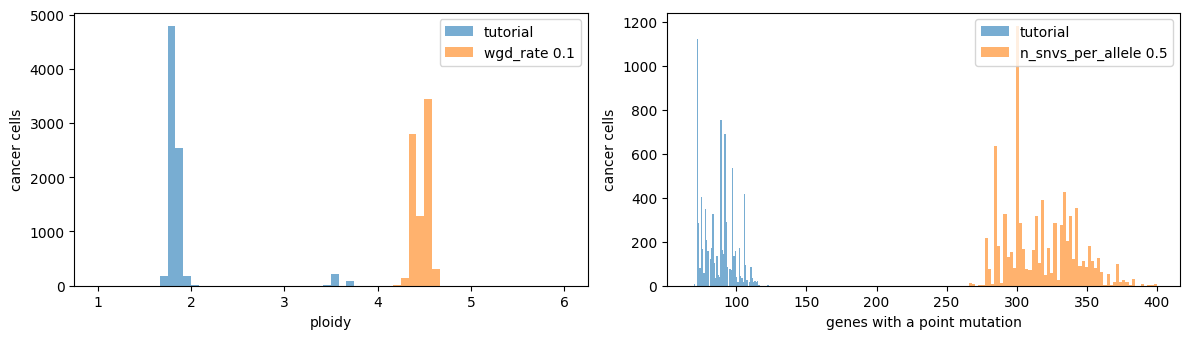

In [5]:
genome["wgd_rate 0.1"] = grow(cancer_cell_params={"wgd_rate": 0.1})
genome["n_snvs_per_allele 0.5"] = grow(cancer_cell_params={"n_snvs_per_allele": 0.5})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for label in ("tutorial", "wgd_rate 0.1"):
    cells = cancer_cells(genome[label], layers=["cell_cnv"])
    axes[0].hist(cells["cell_cnv"].mean(axis=1), bins=60, range=(1, 6), alpha=0.6, label=label)
    print(f"{label}: {cells['cell_wgd']['is_wgd'].mean():.0%} of cancer cells doubled their genome")
for label in ("tutorial", "n_snvs_per_allele 0.5"):
    cells = cancer_cells(genome[label], layers=["cell_snv"])
    axes[1].hist((cells["cell_snv"] > 0).sum(axis=1), bins=60, alpha=0.6, label=label)
axes[0].set_xlabel("ploidy")
axes[1].set_xlabel("genes with a point mutation")
for ax in axes:
    ax.set_ylabel("cancer cells")
    ax.legend()
plt.tight_layout()
plt.show()

At the tutorial `wgd_rate`, 4% of the cancer cells doubled their genome, and the doubled cells form the small group at a ploidy of about 3.5.
At a `wgd_rate` of 0.1, a doubled clone took over and every cancer cell has a ploidy of about 4.5.
Raising `n_snvs_per_allele` from 0.1 to 0.5 raises the number of genes with a point mutation from about 70 to 115 per cell to about 270 to 400.

## Architecture of the tissue

The ductal field places `n_glands` (5) glands of radius `gland_radius` (4 demes), at least `min_gland_sep` (13) demes apart, in a stroma that `stroma_fill_frac` (0.3) fills to a share of its capacity.
The carrying capacity of a gland deme is `K_duct` (60) cells, and that of a stroma deme is `K_stroma` (30).
With `structure_radius` at 0 there are no glands and no stroma, and the tumor grows from the center of an empty field whose demes have a carrying capacity of `carrying_capacity` (30) cells.
Each division sends one daughter to a neighboring deme with probability `dispersal_rate` (0.9).
We grow the tumor in the ductal field and in free growth, and in free growth also at a `dispersal_rate` of 0.1.

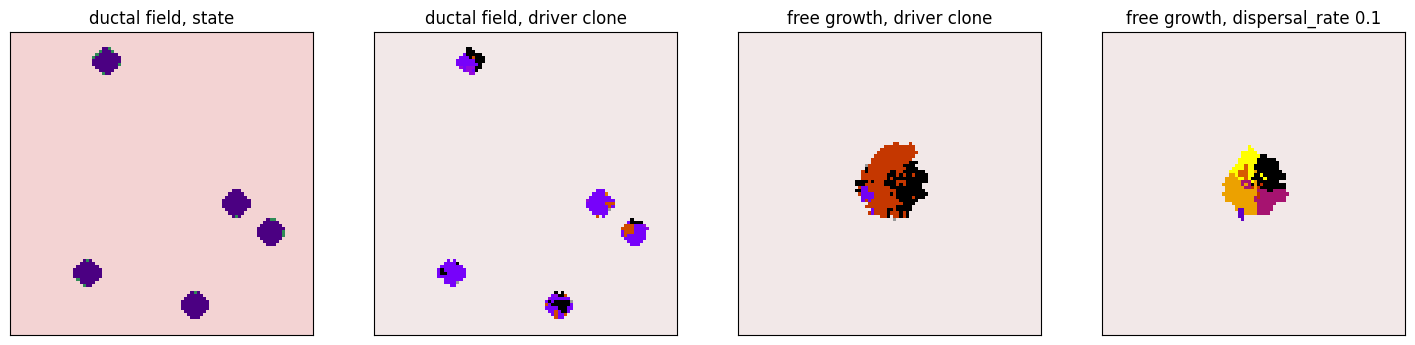

ductal field: 8,005 cancer cells after 206 generations
free growth: 8,005 cancer cells after 217 generations
free growth, dispersal_rate 0.1: 8,017 cancer cells after 233 generations


In [6]:
architecture = {
    "ductal field": selection[1.03],
    "free growth": grow(spatial_params={"structure_radius": 0}),
    "free growth, dispersal_rate 0.1": grow(spatial_params={"structure_radius": 0},
                                            cancer_cell_params={"dispersal_rate": 0.1}),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
architecture["ductal field"].plot_tissue(ax=axes[0], color="state")
for ax, label in zip(axes[1:], architecture):
    architecture[label].plot_tissue(ax=ax, color="clone", min_freq=0.02)
for ax, title in zip(axes, ["ductal field, state", "ductal field, driver clone", "free growth, driver clone",
                            "free growth, dispersal_rate 0.1"]):
    ax.set_title(title)
plt.show()
for label, tumor in architecture.items():
    print(f"{label}: {tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations")

In the ductal field the tumor fills the five glands and has not yet reached the stroma, and a few driver clones share the glands.
In free growth the tumor is a compact disk divided into sectors of driver clones.
At a `dispersal_rate` of 0.1 the tumor took 16 more generations to reach the same size, and more driver clones occupy sectors of their own.

The glands are connected by the intraductal route.
A daughter that leaves a gland jumps to the lumen of another gland with probability kappa / (1 + kappa), where kappa is `cross_gland_kappa` (0.06), and `cross_gland_lambda` (30 demes) sets the length of the distance kernel of the jump.
We switch the route off, and we shorten the kernel to 5 demes.

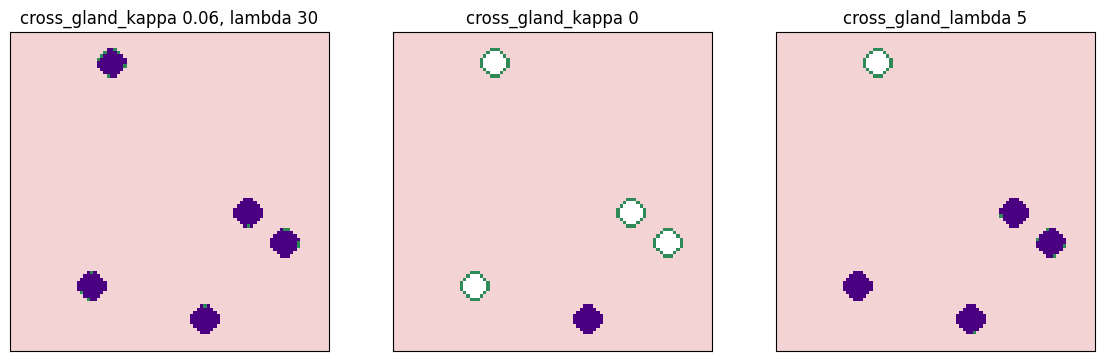

cross_gland_kappa 0.06, lambda 30: 8,005 cancer cells after 206 generations
cross_gland_kappa 0: 2,360 cancer cells after 300 generations
cross_gland_lambda 5: 8,007 cancer cells after 206 generations


In [7]:
spread = {
    "cross_gland_kappa 0.06, lambda 30": selection[1.03],
    "cross_gland_kappa 0": grow(spatial_params={"cross_gland_kappa": 0.0}),
    "cross_gland_lambda 5": grow(spatial_params={"cross_gland_lambda": 5}),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (label, tumor) in zip(axes, spread.items()):
    tumor.plot_tissue(ax=ax, color="state")
    ax.set_title(label)
plt.show()
for label, tumor in spread.items():
    print(f"{label}: {tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations")

Without the intraductal route, the tumor stays in its founding gland and has 2,360 cancer cells after 300 generations.
With a kernel of 5 demes, the tumor colonizes the four glands closest to one another but not the distant gland at the top.

## Selection by the niche

Two traits decide whether cancer cells leave the glands and survive in the stroma.
With `breach_gated_invasion`, a daughter that leaves a gland for the stroma crosses with a probability equal to the breach level of the clone, and stays in the gland otherwise.
In the stroma, resident stromal cells add the death hazard `stromal_hazard` (0.9) times the stromal fraction of the deme times one minus the stromal survival level of the clone.
`prop_breach` and `prop_stromal_survival` (0.002 each) set the share of genes that carry each trait, and `breach_effects` (1.01) and `stromal_survival_effects` (4.0) the effect of a mutated copy.
`breach_cost` (0.6) and `stromal_survival_cost` (0.05) set the fraction of division that each trait costs per unit, wherever it is carried.

We grow the tutorial tumor to 16,000 cancer cells, and the same tumor without the gate and without the stromal hazard.
For each run we report the share of cancer cells in the stroma and the mean levels of the two traits in the cancer cells of the glands and of the stroma.

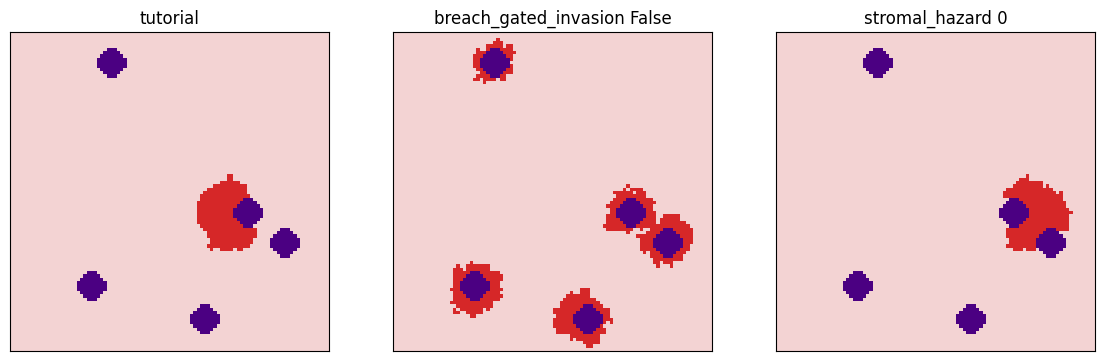

,generations,share in stroma,breach in gland,stromal_survival in gland,breach in stroma,stromal_survival in stroma
tutorial,269.0,0.243,0.0,0.004,0.010,0.002
breach_gated_invasion False,209.0,0.264,0.0,0.001,0.000,0.000
stromal_hazard 0,239.0,0.245,0.0,0.007,0.012,0.002


In [8]:
niche = {
    "tutorial": grow(target_cancer=16_000),
    "breach_gated_invasion False": grow(target_cancer=16_000, spatial_params={"breach_gated_invasion": False}),
    "stromal_hazard 0": grow(target_cancer=16_000, spatial_params={"stromal_hazard": 0.0}),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (label, tumor) in zip(axes, niche.items()):
    tumor.plot_tissue(ax=ax, color="state")
    ax.set_title(label)
plt.show()

rows = {}
for label, tumor in niche.items():
    cells = cancer_cells(tumor)
    place = np.where(cells["cell_gland"]["gland_id"] >= 0, "gland", "stroma")
    traits = cells["cell_evo"][["breach", "stromal_survival"]].groupby(place).mean()
    rows[label] = {"generations": round(tumor.time), "share in stroma": (place == "stroma").mean(),
                   **{f"{trait} in {where}": traits.loc[where, trait] for where in traits.index for trait in traits}}
pd.DataFrame(rows).T.round(3)

The tutorial tumor invaded the stroma from one gland and reached 16,000 cells after 269 generations.
Without the gate, cancer cells invaded the stroma around every gland, and the tumor reached the same size after 209 generations.
Without the stromal hazard, the tumor reached the same size 30 generations earlier than the tutorial tumor, after 239 generations.

With the gate, the cancer cells in the stroma carry breach at a mean level of about 0.01 and the cancer cells in the glands carry almost none, as expected from the selection of breach at the gate.
Without the gate, the cancer cells carry almost no breach in either compartment.
In contrast, the mean stromal survival level stays below 0.01 in both compartments of all three runs, so at this size and seed the stromal hazard delays invasion but does not select for stromal survival in the stroma.
Stromal survival may rise in the stroma in other seeds or at larger sizes, so a study of niche selection should compare several seeds.

## The metastatic site

`met_grid_size` sets the side of a second lattice of host tissue, the metastatic site, which is off at 0.
The carrying capacity of its demes is `K_met` (60) cells, and `host_fill_frac` (0.5) of it is seeded with host cells.
A fraction kappa_m / (1 + kappa_m) of the daughters that leave a stroma deme of the primary are sent to the site, where kappa_m is `met_seed_kappa` (0.03).
The probability of surviving the transit is f + (1 - f) m, where f is `met_transit_floor` (0.001) and m the metastatic survival level of the clone.
At the site, the host cells add the death hazard `met_hazard` (3.5) times the host fraction of the deme times 1 - m.
The configuration already sets the metastatic survival trait (`prop_met_survival` 0.015, `met_survival_effects` 3.0, `met_survival_cost` 0.15), which costs division in the primary and pays off only at the site.
We switch the site on with a lattice as large as the primary and grow to 25,000 cancer cells.
`plot_muller_compartments` shows the clones of the primary and of the metastasis in shared colors, with the clones grouped by their mutated drivers and trait genes.

25,017 cancer cells after 275 generations, 560 of them at the metastatic site
cells placed at the site by seeding: 40
            mean metastatic survival  share with the trait
metastasis                     0.683                 1.000
primary                        0.024                 0.036


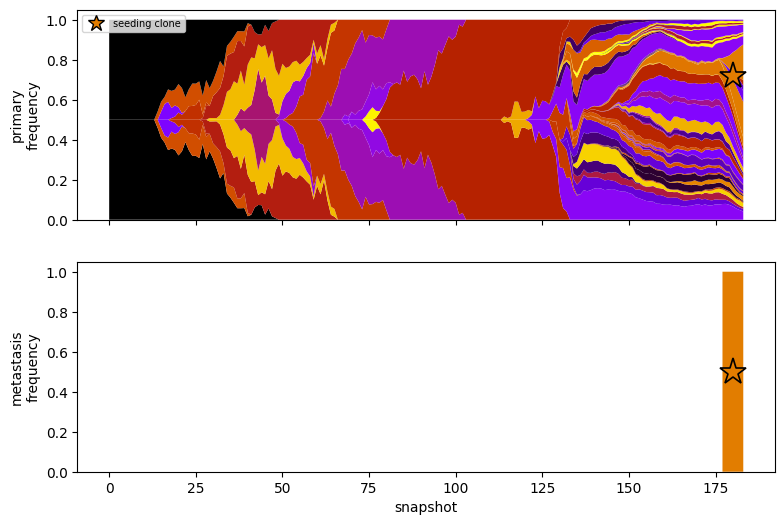

In [9]:
met = grow(target_cancer=25_000, spatial_params={"met_grid_size": 96})
cells = cancer_cells(met)
site = np.where(cells["cell_compartment"]["compartment"] == 1, "metastasis", "primary")
print(f"{met.get_cancer_size():,} cancer cells after {met.time:.0f} generations, {(site == 'metastasis').sum():,} of them at the metastatic site")
print(f"cells placed at the site by seeding: {sum(e['n'] for e in met.events if e.get('event') == 'seeding')}")
print(cells["cell_evo"]["met_survival"].groupby(site).agg(["mean", lambda m: (m > 0).mean()])
      .set_axis(["mean metastatic survival", "share with the trait"], axis=1).round(3))

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
met.plot_muller_compartments(axes=axes, by_drivers=True, min_freq=0.02, normalize=True)
plt.show()

Seeding placed 40 cells at the site, which now contains 560 of the 25,017 cancer cells.
Every cancer cell at the site carries metastatic survival, at a mean level of 0.68, against 3.6% of the cancer cells of the primary, as expected from the selection of the trait by the host hazard.
At the resolution of the plot, the cells at the site belong to one clone, and the star marks the clone of the first seeding cell in both panels.

## Treatment

A therapy acts during growth, through `GenotypeTumor.grow(treatment=...)`.
[`Chemotherapy`](https://pedrofale.github.io/iscc/reference/Chemotherapy/) adds a death hazard to every cancer cell while it is dosed, scaled down by the treatment resistance of the clone.
With `kill_mode="proliferation"`, the hazard is `kill_rate` times the division rate of the clone, so at `kill_rate` 1 a sensitive clone shrinks at the death rate of the clone whatever the division rate.
`toxicity` is the share of the dose that normal cells take.
`start` and `duration` are counted in steps of the run, each of `tau` (0.5) generations.
The other therapies and the shared dosing parameters are on the page of [`Treatment`](https://pedrofale.github.io/iscc/reference/Treatment/).

Resistance arises by mutation in the treatment-resistance genes.
`tutorial_config.yaml` leaves `prop_treatment_resistance` at the package default of 0.1, so that a tenth of all genes carry resistance and the untreated cells reach high resistance levels through passenger mutations, as the run below shows.
We set the resistance genes of the landing animation instead, rare (`prop_treatment_resistance` 0.001) and strong (`treatment_resistant_effects` 2.8), at a cost of 0.3 of division per unit (`treatment_resistance_cost`).
We grow the tumor to 12,000 cancer cells, give a course of 20 generations and follow the tumor for 10 generations after it.

default resistance genes: mean treatment resistance 0.71 in an untreated tumor


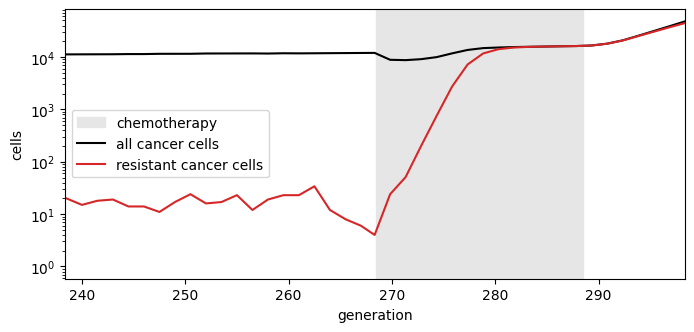

generation 268: 12,007 cancer cells, 4 resistant
generation 288: 16,224 cancer cells, 16,205 resistant
generation 298: 47,794 cancer cells, 44,354 resistant


In [10]:
default_resistance = cancer_cells(selection[1.03])["cell_evo"]["treatment_resistance"]
print(f"default resistance genes: mean treatment resistance {default_resistance.mean():.2f} in an untreated tumor")

resistance = {"prop_treatment_resistance": 0.001, "treatment_resistant_effects": 2.8, "treatment_resistance_cost": 0.3}
treated = grow(target_cancer=12_000, selection_params=resistance)
start = treated.step
chemo = Chemotherapy(start=start, duration=40, kill_rate=0.9, kill_mode="proliferation", effectiveness=1.0, toxicity=0.12)
treated.grow(n_steps=60, treatment=chemo, materialize=False)

def cancer_count(counts, resistant=False):
    return sum(n for g, n in counts.items() if g not in normal_names
               and (not resistant or treated.genotypes[g].evolutionary_parameters["treatment_resistance"] > 0))

time = np.array(treated.trace_times)
total = [cancer_count(tr["genotypes_counts"]) for tr in treated.traces]
resistant = [cancer_count(tr["genotypes_counts"], resistant=True) for tr in treated.traces]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axvspan(start * config["tau"], (start + 40) * config["tau"], color="0.9", label="chemotherapy")
ax.plot(time, total, color="k", label="all cancer cells")
ax.plot(time, resistant, color="tab:red", label="resistant cancer cells")
ax.set_yscale("log")
ax.set_xlim(time[-1] - 60, time[-1])
ax.set_xlabel("generation")
ax.set_ylabel("cells")
ax.legend()
plt.show()
for g in (start * config["tau"], (start + 40) * config["tau"], time[-1]):
    i = int(np.argmin(abs(time - g)))
    print(f"generation {time[i]:.0f}: {total[i]:,} cancer cells, {resistant[i]:,} resistant")

Without treatment, the tumor of the selection section reaches a mean treatment resistance of 0.71, through passenger mutations in the resistance genes of the default layout.
With the rare resistance genes, 4 of the 12,007 cancer cells were resistant when the course started.
The number of cancer cells fell at the start of the course and recovered within about ten generations, as the resistant cells expanded under the drug and made up 16,205 of the 16,224 cancer cells at the end of the course.
After the course, the tumor grew to 47,794 cancer cells in 10 generations, of which 44,354 are resistant.
`kill_rate` and `duration` set the depth and the length of the response of the sensitive cells, and `treatment_resistance_cost` sets how strongly the resistant cells lose against the sensitive cells without the drug.

## Next steps

[Shape the data](03_shape_the_data.ipynb) changes the assays that measure the tumor, and [Simulate a cohort](04_cohort.ipynb) grows many patients over one configuration.